# Video 3: Segmentation and per cell quantification

Notes for this notebook.

This notebook generates the visuals used in the third video of the Multimodal Spatial Biology series. The goal of this video is to go from aligned images to individual cells, using Xenium derived cell boundaries as the shared spatial reference, then turning those boundaries into an actual cells by features table with COMET protein values and gene transcript counts per cell.

All output images are saved into outputs/video3, next to this notebook. That folder is also where the slide deck for this video will be placed.


In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("outputs/video3")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder ready at:", OUTPUT_DIR.resolve())


## Load the dataset

This video needs everything, H and E, COMET, cell boundaries, and transcripts, since the final quantification step merges protein and gene information per cell. This load step takes close to half a minute.


In [3]:
from unumlocalia.io import DatasetLoader
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("data/UnumLocalia")
core_id = "core01_hcc"

t0 = time.time()
loader = DatasetLoader(str(DATA_DIR)).load(
    do_load_transcripts=True,
    load_boundaries=True,
    load_he=True,
    load_comet=True,
)
print("Load time in seconds:", round(time.time() - t0, 1))

markers = loader.comet_markers[core_id]
comet_dapi = loader.get_comet_channel(core_id, markers.index("DAPI"))
print("COMET DAPI shape:", comet_dapi.shape)

%matplotlib inline

Load time in seconds: 22.1
COMET DAPI shape: (4088, 4116)


## Where segmentation comes from

Segmentation means drawing a boundary around each individual cell, so that every pixel or transcript can be assigned to a specific cell rather than treated as part of one large blob of tissue.

We are not computing segmentation ourselves in this video. Xenium already provides per cell boundaries, built from its own imaging during data collection, stored as polygon vertices in micron coordinates. Our job is to bring those boundaries into the same pixel space as COMET, the same kind of coordinate problem we solved in the registration video, so that we can measure COMET protein signal inside each Xenium defined cell.

If you needed to compute segmentation yourself, from a plain fluorescence or H and E image with no provided boundaries, common approaches include Cellpose and StarDist, both of which are deep learning based nucleus and cell segmentation tools with ready to use pretrained models. We will not use them here since this dataset already gives us high quality segmentation, but they are worth knowing about for your own data.


In [4]:
from shapely.geometry import Polygon
from PIL import Image, ImageDraw

def build_cell_label_mask(loader, core_id):
    """
    Transform Xenium cell boundary polygons into COMET pixel space and
    rasterize them into a label mask, one integer label per cell.
    Returns (label_mask, df_cells, polygons_comet_space).
    """
    df_cb = loader.cell_boundaries_df[core_id]

    channel0 = np.asarray(loader.get_comet_channel(core_id, channel_index=0), dtype=float)
    h, w = channel0.shape[:2]

    label_img = Image.new("I", (w, h), 0)
    draw = ImageDraw.Draw(label_img)

    M_fit = np.asarray(loader.transcript_affine_by_core[core_id], dtype=float)
    if M_fit.shape == (2, 3):
        M_fit = np.vstack([M_fit, [0, 0, 1]])

    rows = []
    polygons_comet_space = {}

    for cell_id, group in df_cb.groupby("cell_id"):
        coords_xy = group[["vertex_x", "vertex_y"]].to_numpy(dtype=float)
        if len(coords_xy) < 3:
            continue

        H = np.hstack([coords_xy, np.ones((len(coords_xy), 1))])
        coords_comet = (H @ M_fit.T)[:, :2]

        poly = Polygon(coords_comet)
        if not poly.is_valid or poly.area <= 0:
            continue

        label = len(rows) + 1
        draw.polygon([(float(x), float(y)) for x, y in coords_comet], outline=label, fill=label)

        centroid = poly.centroid
        rows.append({
            "label": label,
            "cell_id": str(cell_id),
            "centroid_x": centroid.x,
            "centroid_y": centroid.y,
        })
        polygons_comet_space[cell_id] = coords_comet

    df_cells = pd.DataFrame(rows)
    label_mask = np.asarray(label_img, dtype=np.int32)

    return label_mask, df_cells, polygons_comet_space


In [5]:
t0 = time.time()
label_mask, df_cells_mask, polygons_comet_space = build_cell_label_mask(loader, core_id)
print("Mask build time in seconds:", round(time.time() - t0, 1))
print("Cells found:", len(df_cells_mask))
print("Label mask shape:", label_mask.shape)


Mask build time in seconds: 3.2
Cells found: 8283
Label mask shape: (4088, 4116)


## A close up look, individual cell outlines on real signal

Before looking at the full tissue, it helps to zoom into a small region and see individual cell boundaries drawn directly on top of the real COMET DAPI signal. This makes the concept of segmentation concrete, each outline is one cell, matched to real nuclear staining underneath it.

Adjust the crop coordinates if the region does not show tissue clearly.


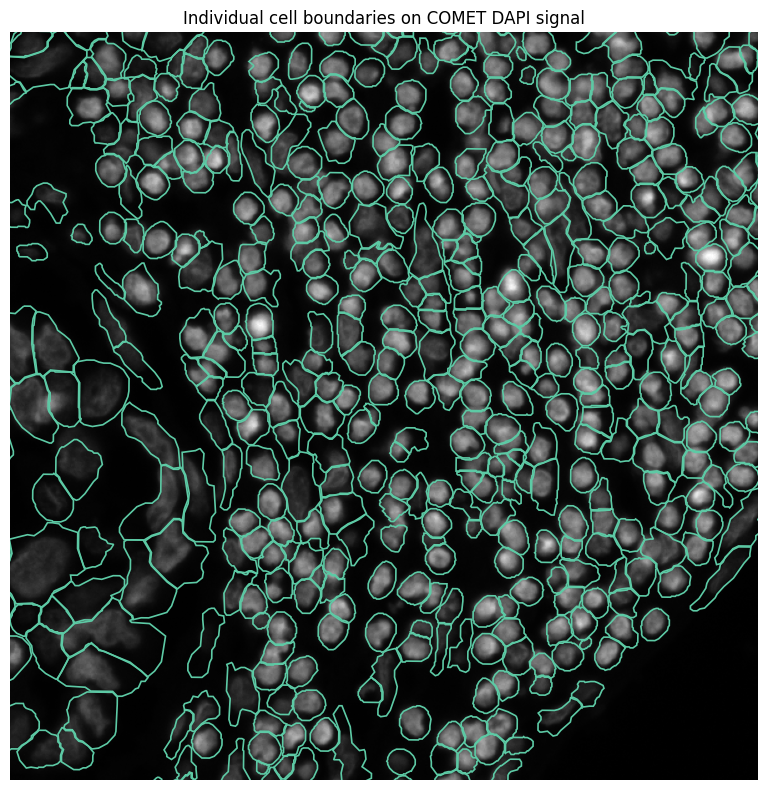

Saved slide_segmentation_closeup.png
If the crop looks empty, adjust crop_x and crop_y to a region where tissue is present.


In [5]:
crop_x, crop_y, crop_size = comet_dapi.shape[1] // 2, comet_dapi.shape[0] // 2, 300
x0, x1 = crop_x - crop_size, crop_x + crop_size
y0, y1 = crop_y - crop_size, crop_y + crop_size

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(comet_dapi[y0:y1, x0:x1], cmap="gray")

for cell_id, coords in polygons_comet_space.items():
    in_crop = (
        (coords[:, 0].min() < x1) and (coords[:, 0].max() > x0)
        and (coords[:, 1].min() < y1) and (coords[:, 1].max() > y0)
    )
    if not in_crop:
        continue
    shifted = coords - np.array([x0, y0])
    polygon_patch = plt.Polygon(shifted, closed=True, fill=False, edgecolor="#5DCAA5", linewidth=1.2)
    ax.add_patch(polygon_patch)

ax.set_title("Individual cell boundaries on COMET DAPI signal")
ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_segmentation_closeup.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_segmentation_closeup.png")
print("If the crop looks empty, adjust crop_x and crop_y to a region where tissue is present.")


## The full segmentation mask

Now the same idea across the whole tissue core, every segmented cell shown as its own randomly colored region. This is the classic way a segmentation result is visualized, and it gives a sense of just how many individual cells we are working with.


c:\Users\m6sbhatt\AppData\Local\anaconda3\envs\unumlocalia-env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


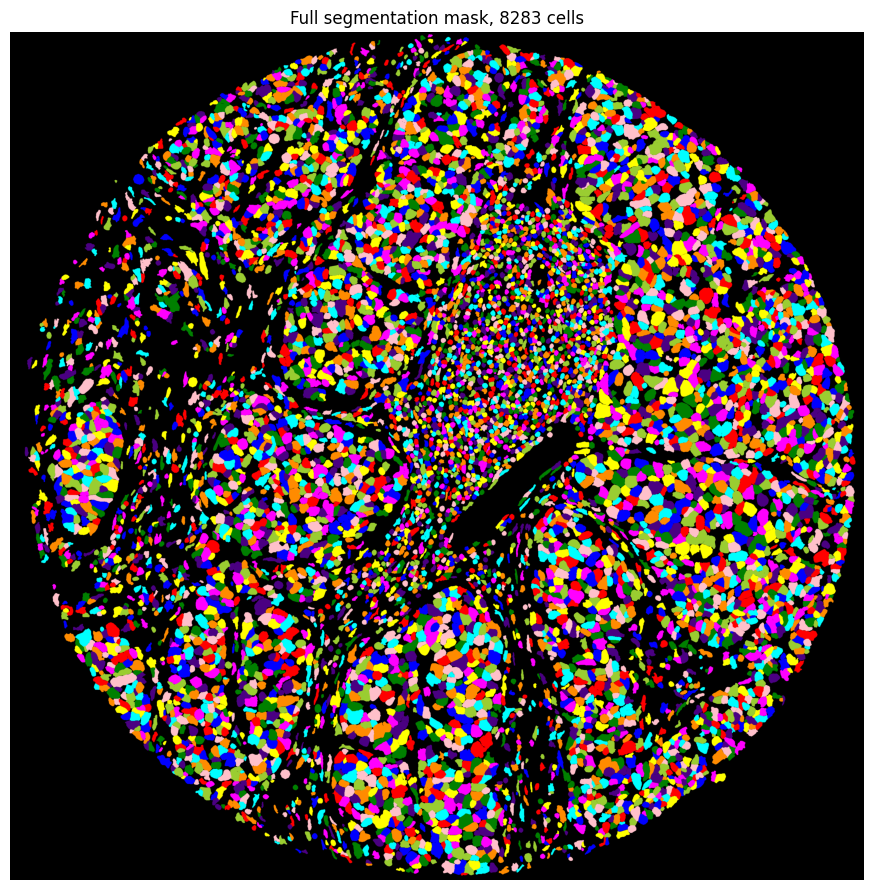

Saved slide_segmentation_full_mask.png


In [6]:
from skimage.color import label2rgb

colored_mask = label2rgb(label_mask, bg_label=0)

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(colored_mask)
ax.set_title(f"Full segmentation mask, {len(df_cells_mask)} cells")
ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_segmentation_full_mask.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_segmentation_full_mask.png")


## From boundaries to numbers, per cell quantification

With cell boundaries in hand, we can now measure signal inside each one. This step averages COMET protein intensity within each cell boundary, and separately counts how many transcripts of each gene fall inside that same boundary, then merges both into a single table, one row per cell.

This is the same function we validated earlier when testing the pipeline, quantify_comet_segmentation, so we already know it works and roughly how long it takes.


In [6]:
t0 = time.time()
df_cells = loader.quantify_comet_segmentation(core_id, method_name="cells")
print("Quantification time in seconds:", round(time.time() - t0, 1))

print("Shape:", df_cells.shape)
print("First 20 columns:", list(df_cells.columns)[:20])
print(df_cells.head())

df_cells.to_csv(OUTPUT_DIR / f"{core_id}_quantification.csv", index=False)
print("Saved quantification CSV.")


Quantification time in seconds: 28.3
Shape: (8283, 5022)
First 20 columns: ['label', 'cell_id', 'centroid_x', 'centroid_y', 'area_px', 'DAPI_mean', 'CK8 - TRITC_mean', 'VEGF - TRITC_mean', 'CD45RA - TRITC_mean', 'vimentin - TRITC_mean', 'E-Cadherin - TRITC_mean', 'CD1c - TRITC_mean', 'IL-10 - TRITC_mean', 'podoplanin - FITC_mean', 'FXIIIa - FITC_mean', 'CD66 - FITC_mean', 'CD20 - TRITC_mean', 'αSMA - TRITC_mean', 'CD45 - TRITC_mean', 'HepPar1 - TRITC_mean']
   label     cell_id   centroid_x   centroid_y     area_px   DAPI_mean  \
0      1  dmigmofe-1  3681.090729  1383.901552  629.885041  517.412873   
1      2  dmihaakf-1  3697.999024  1413.818488  613.673721  546.381250   
2      3  dmihbjom-1  3676.573671  1410.634430  575.132490  445.033113   
3      4  dmihdcag-1  3696.796593  1378.232152  275.983261  315.247458   
4      5  dmihhboi-1  3694.852791  1440.253496  662.311011  604.377778   

   CK8 - TRITC_mean  VEGF - TRITC_mean  CD45RA - TRITC_mean  \
0       1102.784929           

## Summary

We now have two things worth carrying into the next video. First, a reusable way to turn Xenium boundaries into a segmentation mask in COMET pixel space, build_cell_label_mask, which also gives us cell outlines for visualization. Second, a full cells by features table, protein means and gene counts together, for every one of the roughly eight thousand cells in this core.

Next episode, we use this table to answer an actual biological question, looking at where specific markers are expressed across the tissue, and what that tells us about the underlying biology.
